# Select-DPC: our offline dataset — 100 development seeds

A separate copy for **seeds 211–310**, **configurable T_sim (currently 100)**, using **our offline dataset** (`data/reacher/select_iid_offline_hankel.npy`). This does not modify or reuse the authors-data experiment or the 500 held-out evaluation seeds.

Only the offline dataset changes. Select-DPC retains the upstream controller, weights, constraints, final Cartesian target, Reacher-v4 environment, 200 selected columns, five refinements, T_ini=2, T_f=15, and Clarabel. No Atlas controller or Atlas-generated reference is used.

Our source stores 200 episodes of 200 samples as L=12 windows. The adapter verifies overlaps, reconstructs each episode, keeps its eight physical outputs (drops the two derived trigonometric features), reorders outputs to the native Select-DPC order, and lets upstream rebuild L=17 windows **within each episode**: 36,800 candidate columns. Inputs are unchanged; exploration is ±1. Post-action output/input pairing is preserved. No upstream raw-observation correction is applied to these already-physical outputs.

Start with `RUN_EXPERIMENT=False` and run the read-only preflight. Set it to `True` only when ready to run a batch. Original notebooks, datasets, and results remain untouched. Statistics use only completed rollouts of the selected length in this copy's separate result directory.


In [1]:
from pathlib import Path
import json, os, sys, subprocess, signal, hashlib, fcntl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/atlas_deepc/benchmarks/select_dpc_our_data.py").is_file())
RUNNER = ROOT / "src/atlas_deepc/benchmarks/select_dpc_our_data.py"
# Use the existing isolated environment: includes the upstream torch dependency.
PYTHON = ROOT / "tmp/select_dpc_upstream_env/bin/python"
SEED_START, SEED_STOP, T_sim = 211, 310, 100
STEPS = T_sim
assert isinstance(T_sim, int) and T_sim >= 100, "T_sim must be at least 100 for the last-100 success window"
RESULT_DIR = ROOT / f"experiments/reacher/select_dpc_our_data_clarabel_211_310_t{T_sim}_v1"
# Each invocation stops after this many NEW complete seeds.
BATCH_SIZE = 100  # New rollouts this session; the duration estimate is printed below.
BLOCK_NUMBER = None  # None: next unfinished seeds; 1, 2, ...: a specific numbered block.
RUN_EXPERIMENT = True  # Explicit opt-in; opening this notebook does not start a run.

def batch_bounds():
    assert isinstance(BATCH_SIZE, int) and BATCH_SIZE > 0, 'BATCH_SIZE must be a positive integer'
    if BLOCK_NUMBER is None:
        return SEED_START, SEED_STOP
    count = (SEED_STOP - SEED_START + BATCH_SIZE) // BATCH_SIZE
    assert isinstance(BLOCK_NUMBER, int) and 1 <= BLOCK_NUMBER <= count, f'Choose block 1–{count}'
    start = SEED_START + (BLOCK_NUMBER - 1) * BATCH_SIZE
    return start, min(start + BATCH_SIZE - 1, SEED_STOP)

def worker_running():
    if not (RESULT_DIR / "run.lock").exists():
        return False
    with (RESULT_DIR / "run.lock").open("r") as lock:
        try:
            fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            return True
        else:
            fcntl.flock(lock, fcntl.LOCK_UN)
            return False

print(f"Requested seeds: {SEED_START}–{SEED_STOP} ({SEED_STOP-SEED_START+1} seeds); {STEPS} control steps")
print("Results:", RESULT_DIR)
print("Background worker active:", worker_running())
print("Resume enabled:", RUN_EXPERIMENT)

block_start, block_stop = batch_bounds()
missing = [s for s in range(block_start, block_stop + 1)
           if not (RESULT_DIR / f'seed{s}_control_results.npz').exists()]
planned = missing[:BATCH_SIZE]
print('Batch mode:', 'next unfinished seeds' if BLOCK_NUMBER is None else f'block {BLOCK_NUMBER}')
print('Seeds planned:', planned)
print(f'Rough estimate using the previous dataset timing (remeasure for this dataset): {len(planned) * STEPS * 1.6 / 3600:.2f} hours, plus overhead')


Requested seeds: 211–310 (100 seeds); 100 control steps
Results: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/reacher/select_dpc_our_data_clarabel_211_310_t100_v1
Background worker active: False
Resume enabled: True
Batch mode: next unfinished seeds
Seeds planned: [256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]
Rough estimate using the previous dataset timing (remeasure for this dataset): 2.44 hours, plus overhead


## Preserved Select-DPC settings

| Setting | This Select-DPC run |
|---|---|
| Offline data | Our `select_iid_offline_hankel.npy`; 200 × 200 samples; exploration ±1; physical p=8; rebuilt L=17 |
| Environment / initialization | Original Reacher-v4; repeated-state controller initialization; no physical warmup |
| Outputs / horizon | Original eight outputs; past 2, future 15 |
| Selection | Original L1 trajectory selector; 200 raw columns; five refinement solves |
| QP | Original objective, projection regularization, L1 penalties, affine sum constraint, and fallback behavior |
| Reference | Original `DefaultReacherSetpoint`: each seed’s final Cartesian target; no waypoints |
| Constraints | Original input ±0.5 and predicted fingertip height ≤0.1 m |
| Solver adapter | Clarabel; `max_iter=6000`, `warm_start=False`, default tolerances, one solver thread, internal KKT stabilization `static_regularization_constant=1e-6` |
| Timing | Entire control call, all five refinements and QP construction/pseudoinverse; excludes environment stepping and file writes; includes instrumentation overhead |

The original authors-data pilot required the retained internal stabilization setting. The documented solver setting changes numerical factorization, **not** the controller objective or its regularization weights. Solver statuses and constraint residuals are saved.

**Success matches the Atlas baseline:** both the last-30 and last-100 windows must have mean fingertip error <10 mm and maximum error <20 mm. At T_sim=100, the last-100 window covers the entire rollout. Shorter rollouts are not directly comparable with 300-step results. Partial results describe completed seeds only.

**Cost warning:** saved closed-loop stage costs use Select-DPC’s own Q/R, evaluated on post-action outputs like the baseline. Do not directly rank these against Atlas costs with different Q/R. Raw traces and unweighted XY/input metrics are retained for common rescoring. Targets above the original height constraint are flagged.


## Read-only dataset preflight

Checks the actual dataset conversion, upstream source, and Clarabel installation without running a rollout or creating a results directory.


In [2]:
assert PYTHON.is_file(), f"Missing isolated interpreter: {PYTHON}"
check = subprocess.run([str(PYTHON), "-m", "atlas_deepc.benchmarks.select_dpc_our_data", "--preflight", "--steps", str(STEPS)],
    cwd=ROOT, env=dict(os.environ, PYTHONPATH=str(ROOT / "src")),
    capture_output=True, text=True)
print(check.stdout)
if check.returncode:
    print(check.stderr)
check.check_returncode()


{
  "preflight": "passed",
  "rollouts_started": 0,
  "episodes": 200,
  "library_columns": 36800,
  "p": 8,
  "T_ini": 2,
  "T_f": 15,
  "seed_start": 211,
  "seed_stop": 310,
  "steps": 100,
  "data_sha256": "75c6e2e8376c00ac1fc032ecaaa31b9a3eb830b671f68a18e559b22f9263c45b",
  "source_round_trip_max_error": 0.0
}



In [3]:
manifest_path = RESULT_DIR / "manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    expected = manifest["runner_sha256"]
    actual = hashlib.sha256(RUNNER.read_bytes()).hexdigest()
    print("Runner matches saved protocol:", actual == expected)
    print("Upstream commit:", manifest["upstream_commit"])
    print("Clarabel settings:", manifest["clarabel_options"])
    print("Interpreter available:", PYTHON.is_file())
    print("Requested seeds:", manifest["seed_start"], "through", manifest["seed_stop"])
else:
    print("No saved manifest yet.")
progress_path = RESULT_DIR / "progress.json"
if progress_path.exists():
    progress = json.loads(progress_path.read_text())
    print("Latest checkpoint:", progress)
print("Worker currently active:", worker_running())


Runner matches saved protocol: True
Upstream commit: 8afa3b36ca47570400b0b8ff82328ab25ee3fdee
Clarabel settings: {'max_threads': 1, 'static_regularization_constant': 1e-06}
Interpreter available: True
Requested seeds: 211 through 310
Latest checkpoint: {'state': 'interrupted', 'seed': 256, 'completed': 45, 'requested': 100, 'completed_this_batch': 45, 'updated_unix': 1792440791.6054342, 'note': 'Completed seeds preserved; rerun the same batch to resume.'}
Worker currently active: False


## Run one batch / resume

Keep the panel fixed at **211–310**, with **configurable T_sim (currently 100)**. Choose **T_sim >= 100** for the rollout length. The result directory automatically includes that length, so 100-step and 300-step traces never mix. Change **BATCH_SIZE** and optionally **BLOCK_NUMBER** to control sessions. Re-run the settings cell after editing T_sim.

- Example: `BATCH_SIZE=25`, `BLOCK_NUMBER=None`: run the next 25 unfinished seeds, then exit. Run the same cell later to continue.
- With batch size 25, numbered blocks are: `1`: 211–235; `2`: 236–260; `3`: 261–285; `4`: 286–310. Completed seeds are skipped.
- To run all 100 in one session, set `BATCH_SIZE=100`, `BLOCK_NUMBER=None`.
- Set `RUN_EXPERIMENT=True` when ready. No later batches start automatically.
- At 100 steps and the previous dataset's 1.6 seconds/step, 100 rollouts would take about 4 h 27 min. At 300 steps, about 13 h 20 min. **Timing may change with our dataset.**
- Completed seeds are saved individually; an interrupted seed restarts at step 1. Wait for the child to stop before closing the notebook or sleeping the laptop.
- Statistics combine all completed seeds across batches. `complete=true` requires all 100; `batch_complete` only marks this session.
- Run sequentially with other controllers for comparable timing. This notebook does not stop other jobs.

Keep the notebook open while running. Logs append to `notebook_run.log`. Do not change the runner, dataset, or protocol between batches, or bypass a manifest mismatch.


In [4]:
block_start, block_stop = batch_bounds()
command = [str(PYTHON), "-u", "-m", "atlas_deepc.benchmarks.select_dpc_our_data",
           "--seed-start", str(SEED_START), "--seed-stop", str(SEED_STOP),
           "--steps", str(STEPS), "--output-dir", str(RESULT_DIR),
           "--block-start", str(block_start), "--block-stop", str(block_stop),
           "--max-new-seeds", str(BATCH_SIZE)]
manifest_path = RESULT_DIR / "manifest.json"
if not RUN_EXPERIMENT:
    print("Skipped. Set RUN_EXPERIMENT = True above, then run this cell to run one batch.")
    print(" ".join(command))
else:
    assert PYTHON.is_file(), f"Missing isolated interpreter: {PYTHON}"
    assert not worker_running(), "Another worker is already using this output directory."
    if manifest_path.exists():
        saved = json.loads(manifest_path.read_text())
        assert hashlib.sha256(RUNNER.read_bytes()).hexdigest() == saved["runner_sha256"], "Runner changed; do not mix protocols."
        assert (SEED_START, SEED_STOP, STEPS) == (saved["seed_start"], saved["seed_stop"], saved["steps"])
    run_env = dict(os.environ, PYTHONPATH=str(ROOT / "src"))
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    with (RESULT_DIR / "notebook_run.log").open("a", buffering=1) as log:
        process = subprocess.Popen(command, cwd=ROOT, env=run_env, stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True, bufsize=1, start_new_session=True, stdin=subprocess.DEVNULL)
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
            returncode = process.wait()
            if returncode:
                raise subprocess.CalledProcessError(returncode, command)
        except KeyboardInterrupt:
            if process.poll() is None:
                process.send_signal(signal.SIGINT)
            print("\nInterrupt requested. Waiting for the child to stop; completed seeds remain saved.")
            try:
                process.wait(timeout=60)
            except subprocess.TimeoutExpired:
                print(f"Worker PID {process.pid} is still stopping. Do not start another run until its lock is released.")
            raise


Our offline data: 200 episodes, 36,800 L=17 columns; unchanged 200-column/five-refinement Select-DPC.
Panel: 45/100 already complete. This invocation: 55 new seeds, 100 steps each.
/Users/kumiko/miniconda3/envs/gym-robotics-mujoco/lib/python3.10/site-packages/gymnasium/envs/registration.py:512: DeprecationWarning: WARN: The environment Reacher-v4 is out of date. You should consider upgrading to version `v5`.
  logger.deprecation(
seed 256 step 1/100: error=357.85 mm
seed 256 step 20/100: error=85.15 mm
seed 256 step 40/100: error=1.86 mm
seed 256 step 60/100: error=10.24 mm
seed 256 step 80/100: error=10.77 mm
seed 256 step 100/100: error=11.08 mm
46/100 complete: seed 256, success=False, final100=54.246 mm, successes=0/46, median compute=1278.7 ms; this batch 1/55
/Users/kumiko/miniconda3/envs/gym-robotics-mujoco/lib/python3.10/site-packages/gymnasium/envs/registration.py:512: DeprecationWarning: WARN: The environment Reacher-v4 is out of date. You should consider upgrading to version

## Saved results — safe to rerun independently

This reads completed per-seed files, even when the full batch is unfinished. Timing columns below pool all completed control steps; the first-five-step-discard convention is also shown. Costs are unscaled Select-DPC realized stage costs, not QP objectives.


In [5]:
rows = []
for seed in range(SEED_START, SEED_STOP + 1):
    path = RESULT_DIR / f"seed{seed}_control_results.npz"
    if path.exists():
        with np.load(path) as trace:
            row = json.loads(trace["summary"].item())
            assert row['seed'] == seed and row['steps'] == STEPS, 'Incompatible saved rollout'
            assert len(trace['distance']) == len(trace['control_compute_time_s']) == STEPS, 'Incomplete saved rollout'
        row["result_path"] = str(path)
        rows.append(row)
if rows:
    df = pd.DataFrame(rows)
    display(pd.DataFrame({
        "seed": df.seed, "success": df.strict_success,
        "mean_final100_mm": 1000*df.mean_last_100,
        "mean_prediction_mm": 1000*df.mean_prediction_error_xy,
        "closed_loop_cost": df.closed_loop_reference_cost,
        "median_compute_ms": df.median_control_compute_time_ms,
        "p99_compute_ms": df.p99_control_compute_time_ms,
        "max_compute_ms": df.max_control_compute_time_ms,
        "failed_final_solves": df.unsolved_steps,
        "failed_refinements": df.unsolved_refinements,
        "target_above_height_limit": df.target_above_original_height_constraint,
    }).round(3))
    timing_all, timing_trimmed = [], []
    for row in rows:
        with np.load(row["result_path"]) as trace:
            timing_all.append(1000*trace["control_compute_time_s"])
            timing_trimmed.append(1000*trace["control_compute_time_s"][5:])
    timing_rows = []
    for label, arrays in [("All steps", timing_all), ("Discard first 5 per seed", timing_trimmed)]:
        values = np.concatenate(arrays)
        timing_rows.append({"timing_scope": label, "mean_ms": values.mean(),
                           "median_ms": np.median(values), "p95_ms": np.percentile(values, 95),
                           "p99_ms": np.percentile(values, 99), "max_ms": values.max()})
    display(pd.DataFrame(timing_rows).round(3))
    print(f"Completed: {len(rows)}/{SEED_STOP-SEED_START+1}; successes: {int(df.strict_success.sum())}/{len(rows)}")
    print("Worker active:", worker_running())
else:
    print("No completed seed files yet.")


,seed,success,mean_final100_mm,mean_prediction_mm,closed_loop_cost,median_compute_ms,p99_compute_ms,max_compute_ms,failed_final_solves,failed_refinements,target_above_height_limit
0,211,False,34.642,1.918,4965.312,1107.542,1362.861,1494.772,0,0,False
1,212,False,84.874,4.970,54416.748,1098.676,1214.751,1221.946,0,0,False
2,213,False,114.383,6.539,70953.750,1336.870,1806.015,2001.388,0,0,True
3,214,False,114.326,7.500,73141.403,1393.791,1943.897,2050.554,0,0,True
4,215,False,34.303,2.118,17841.461,1104.980,1516.685,1748.426,0,0,False
...,...,...,...,...,...,...,...,...,...,...,...
95,306,False,103.896,12.199,103164.124,1166.384,1518.273,1670.457,0,0,False
96,307,False,60.644,3.441,40754.504,1224.124,1664.811,1699.395,0,0,False
97,308,False,57.067,3.142,38793.142,1168.732,1499.792,1636.587,0,0,False
98,309,False,155.112,12.854,133317.847,1342.989,1783.604,1809.809,0,0,False


,timing_scope,mean_ms,median_ms,p95_ms,p99_ms,max_ms
0,All steps,1335.933,1283.064,1766.522,2270.687,8742.498
1,Discard first 5 per seed,1333.155,1282.786,1768.239,2253.993,8057.749


Completed: 100/100; successes: 0/100
Worker active: False


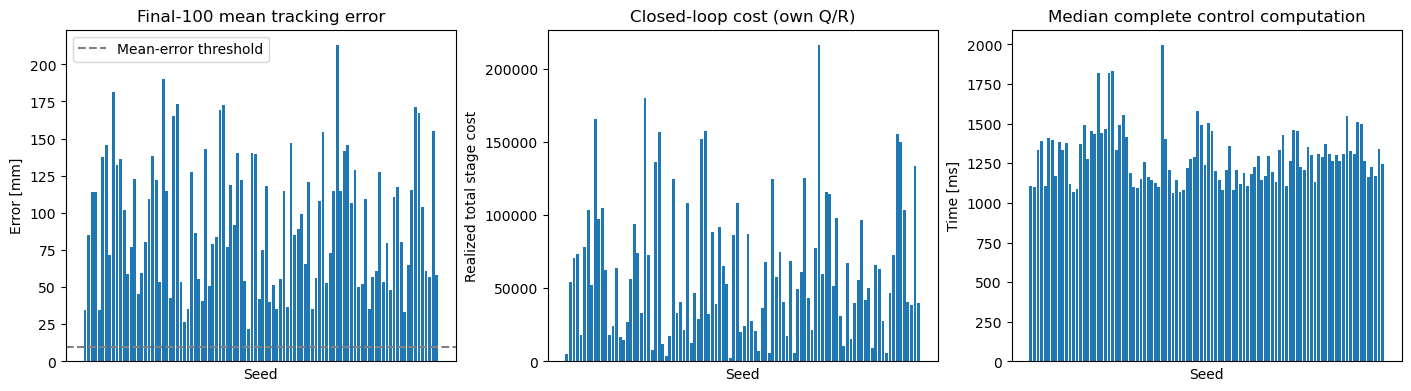

In [6]:
if rows:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
    axes[0].bar(df.seed.astype(str), 1000*df.mean_last_100)
    axes[0].set(title="Final-100 mean tracking error", ylabel="Error [mm]", xlabel="Seed")
    axes[0].axhline(10, color="grey", linestyle="--", label="Mean-error threshold")
    axes[0].legend()
    axes[1].bar(df.seed.astype(str), df.closed_loop_reference_cost)
    axes[1].set(title="Closed-loop cost (own Q/R)", ylabel="Realized total stage cost", xlabel="Seed", ylim=(0, None))
    axes[2].bar(df.seed.astype(str), df.median_control_compute_time_ms)
    axes[2].set(title="Median complete control computation", ylabel="Time [ms]", xlabel="Seed", ylim=(0, None))
    if len(rows) > 15:
        for ax in axes:
            ax.set_xticks([])
    plt.show()


## Inspect one completed rollout

The plot uses post-action fingertip errors and predictions aligned to that same output sample. The computation trace includes all five refinements. Change `PLOT_SEED` to inspect another completed seed.


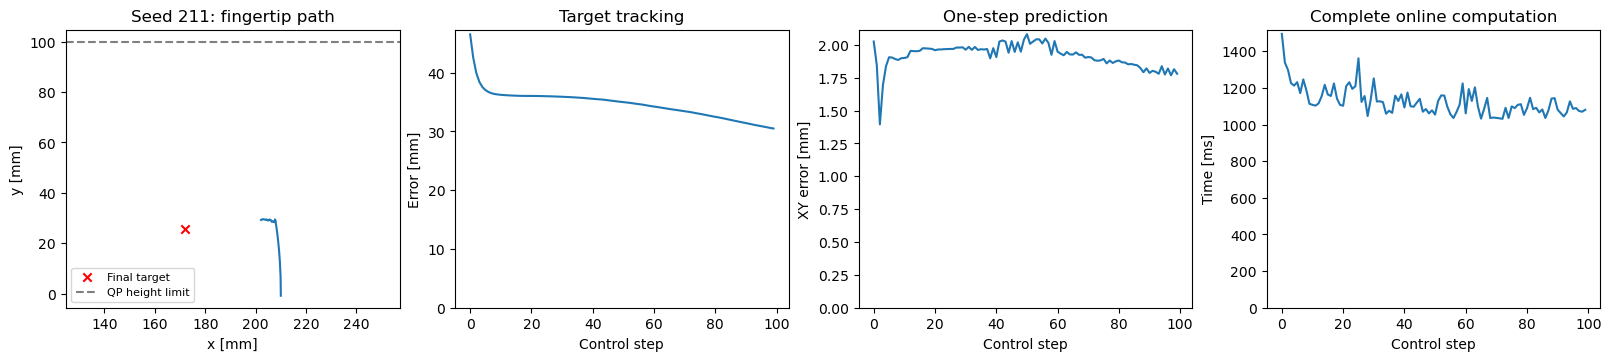

In [7]:
PLOT_SEED = SEED_START
path = RESULT_DIR / f"seed{PLOT_SEED}_control_results.npz"
if path.exists():
    with np.load(path) as trace:
        assert json.loads(trace['summary'].item())['steps'] == STEPS, 'Incompatible saved rollout'
        y, ref, target = trace["y"], trace["ref"], trace["target_xy"]
        distance = trace["distance"]
        prediction_error = trace["prediction_error_xy"]
        compute_ms = 1000*trace["control_compute_time_s"]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
    axes[0].plot(1000*y[:, 6], 1000*y[:, 7])
    axes[0].scatter(*(1000*target), marker="x", c="red", label="Final target")
    axes[0].axhline(100, color="grey", linestyle="--", label="QP height limit")
    axes[0].set(title=f"Seed {PLOT_SEED}: fingertip path", xlabel="x [mm]", ylabel="y [mm]")
    axes[0].axis("equal")
    axes[0].legend(fontsize=8)
    axes[1].plot(1000*distance)
    axes[1].set(title="Target tracking", xlabel="Control step", ylabel="Error [mm]", ylim=(0, None))
    axes[2].plot(1000*prediction_error)
    axes[2].set(title="One-step prediction", xlabel="Control step", ylabel="XY error [mm]", ylim=(0, None))
    axes[3].plot(compute_ms)
    axes[3].set(title="Complete online computation", xlabel="Control step", ylabel="Time [ms]", ylim=(0, None))
    plt.show()
else:
    print(f"Seed {PLOT_SEED} has not completed.")
